# DA-015: Online Learning Engagement Analysis

**Domain:** EdTech / Learning Analytics  **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Objectives
1. Prepare a clean learner-activity dataset (1000 synthetic learners, 5 course modules).
2. Measure completion rate, quiz performance and learning time.
3. Compare performance by **module**, **device** and **age group**.
4. Build a transparent **engagement score** and category.
5. Explore relationships between engagement and outcomes.
6. Produce evidence-based insights and recommendations.

> **Note:** The dataset is synthetic. It contains no real student personal information.

## 1. Setup
Import the libraries and the project's own modules from the `src/` folder.

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable whether the notebook runs from notebooks/ or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
import numpy as np
from IPython.display import Image, Markdown, display

import config
from generate_data import get_raw_dataset
from data_cleaning import clean_data, build_data_dictionary
from engagement import add_engagement_score
from analysis import run_eda
import visualization as viz
from insights import generate_insights, save_insights

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Project root:", PROJECT_ROOT)

Project root: /home/chandan/Desktop/github/DA-015-Online-Learning-Engagement-Analysis


## 2. Load the Dataset
If `dataset/online_learning.csv` already exists it is **reused**; otherwise a synthetic dataset is generated.

In [2]:
raw = get_raw_dataset()
print("Raw shape:", raw.shape)
raw.head()

[data] Reusing existing dataset: dataset/online_learning.csv
Raw shape: (1012, 13)


,learner_id,age_group,course_module,device_type,time_spent_hours,videos_watched,videos_available,lessons_completed,lessons_available,quiz_score,completion_status,activity_count,last_active_days
0,L0632,35-44,Web Development,Desktop,5.3,3,75,5,50,29.1,Dropped,8.0,70.0
1,L0635,18-24,Python,Mobile,5.8,39,60,19,40,37.2,In Progress,30.0,21.0
2,L0964,18-24,Python,Mobile,8.8,21,60,12,40,60.7,Dropped,30.0,105.0
3,L0626,25-34,SQL,Laptop,NaN,35,45,22,30,56.4,In Progress,46.0,2.0
4,L0366,25-34,data analytics,Desktop,8.1,28,60,19,40,50.7,In Progress,43.0,4.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   learner_id         1012 non-null   str    
 1   age_group          1012 non-null   str    
 2   course_module      1012 non-null   str    
 3   device_type        1012 non-null   str    
 4   time_spent_hours   980 non-null    float64
 5   videos_watched     1012 non-null   int64  
 6   videos_available   1012 non-null   int64  
 7   lessons_completed  1012 non-null   int64  
 8   lessons_available  1012 non-null   int64  
 9   quiz_score         1012 non-null   float64
 10  completion_status  1012 non-null   str    
 11  activity_count     962 non-null    float64
 12  last_active_days   992 non-null    float64
dtypes: float64(4), int64(4), str(5)
memory usage: 102.9 KB


### 2.1 Initial Data-Quality Check
Before cleaning: missing values, duplicates, invalid scores and inconsistent labels.

In [4]:
quality = pd.DataFrame({
    "missing_values": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
})
print("Exact duplicate rows:", raw.duplicated().sum())
print("Quiz scores outside 0-100:", ((raw["quiz_score"] < 0) | (raw["quiz_score"] > 100)).sum())
quality[quality["missing_values"] > 0]

Exact duplicate rows: 12
Quiz scores outside 0-100: 6


,missing_values,missing_pct
time_spent_hours,32,3.16
activity_count,50,4.94
last_active_days,20,1.98


In [5]:
for col in ["course_module", "device_type", "completion_status", "age_group"]:
    print(f"{col}: {sorted(raw[col].astype(str).unique())}")

course_module: [' java', 'Data Analytics', 'Java', 'Python', 'SQL', 'SQL ', 'Web Development', 'data analytics', 'python', 'web dev']
device_type: [' Laptop ', 'DESKTOP', 'Desktop', 'Laptop', 'Mobile', 'Tablet', 'mobile', 'tablet']
completion_status: ['Completed', 'DROPPED', 'Dropped', 'In Progress', 'completed', 'in progress']
age_group: ['18-24', '25-34', '35-44', '45+']


## 3. Data Cleaning
The `clean_data()` function standardises categories, removes duplicates, sets invalid quiz scores to missing,
caps impossible values and imputes missing numbers with the **module-level median**. Every action is logged.

In [6]:
clean = clean_data(raw)
print("\nCleaned shape:", clean.shape)
print("Remaining missing values:", clean.isna().sum().sum())
print("Duplicate learner IDs:", clean["learner_id"].duplicated().sum())
print("Quiz score range:", clean["quiz_score"].min(), "-", clean["quiz_score"].max())

[clean] Raw dataset: 1012 rows x 13 columns
[clean] Missing values in raw data: time_spent_hours=32, activity_count=50, last_active_days=20
[clean] course_module: standardised 8 inconsistent label(s); 0 unrecognised value(s)
[clean] device_type: standardised 8 inconsistent label(s); 0 unrecognised value(s)
[clean] completion_status: standardised 8 inconsistent label(s); 0 unrecognised value(s)
[clean] age_group: standardised 0 inconsistent label(s); 0 unrecognised value(s)
[clean] Removed 12 exact duplicate row(s)
[clean] Removed 0 additional duplicate learner_id row(s)
[clean] quiz_score: 6 invalid value(s) outside 0-100 set to missing (values: [-12.0, -5.0, 101.5, 105.0, 120.0, 150.0])
[clean] lessons_completed: 4 value(s) greater than lessons_available capped
[clean] videos_watched: 0 value(s) greater than videos_available capped
[clean] time_spent_hours: imputed 30 missing value(s) with module-level median
[clean] quiz_score: imputed 6 missing value(s) with module-level median
[cle

### 3.1 Data Dictionary

In [7]:
dictionary = build_data_dictionary()
dictionary

,column,source,data_type,description,valid_values
0,learner_id,Raw,Text,Artificial unique learner identifier (no perso...,L0001 - L1000
1,age_group,Raw,Category,Learner age band,"18-24, 25-34, 35-44, 45+"
2,course_module,Raw,Category,Course module enrolled in,"Python, Java, SQL, Web Development, Data Analy..."
3,device_type,Raw,Category,Main device used for learning,"Laptop, Mobile, Desktop, Tablet"
4,time_spent_hours,Raw,Decimal,Total learning time on the platform (hours),>= 0
5,videos_watched,Raw,Integer,Number of course videos watched,0 - videos_available
6,videos_available,Raw,Integer,Number of videos in the module,> 0
7,lessons_completed,Raw,Integer,Number of lessons completed,0 - lessons_available
8,lessons_available,Raw,Integer,Number of lessons in the module,> 0
9,quiz_score,Raw,Decimal,Average quiz score (%),0 - 100


## 4. Engagement Score
A transparent, weighted score built from three behaviours. Each one is clipped to its 5th–95th percentile and
then min-max scaled to 0–1:

$$\text{engagement} = 100 \times (0.35\cdot\text{activity} + 0.35\cdot\text{time} + 0.30\cdot\text{lesson progress})$$

| Category | Score range |
|---|---|
| Low | < 40 |
| Medium | 40 – 69.9 |
| High | ≥ 70 |

Quiz score and completion are **not** part of the score, so we can test whether engagement predicts them.

In [8]:
data = add_engagement_score(clean)
data[["learner_id", "activity_count", "time_spent_hours", "lesson_progress_pct",
      "engagement_score", "engagement_category"]].head(10)

,learner_id,activity_count,time_spent_hours,lesson_progress_pct,engagement_score,engagement_category
0,L0001,40,9.4,31.4,23.3,Low
1,L0002,37,22.4,55.0,42.1,Medium
2,L0003,71,23.3,68.9,60.4,Medium
3,L0004,78,13.1,80.0,57.5,Medium
4,L0005,47,18.5,22.0,31.1,Low
5,L0006,39,10.6,42.5,27.8,Low
6,L0007,91,25.9,100.0,80.9,High
7,L0008,34,18.2,35.0,30.4,Low
8,L0009,46,26.9,62.0,52.0,Medium
9,L0010,31,24.6,42.0,37.5,Low


In [9]:
data["engagement_category"].value_counts().reindex(config.ENGAGEMENT_LABELS).to_frame("learners")

,learners
engagement_category,
Low,488
Medium,308
High,204


## 5. Exploratory Data Analysis
### 5.1 Key Performance Indicators

In [10]:
results = run_eda(data)
pd.Series(results["kpis"], name="value").to_frame()

,value
total_learners,1000.0
completed_learners,210.0
completion_rate_pct,21.0
dropout_rate_pct,31.1
in_progress_pct,47.9
avg_quiz_score,53.3
median_quiz_score,53.8
total_learning_hours,17255.6
avg_learning_hours,17.3
avg_lesson_progress_pct,57.1


In [11]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_spent_hours,1000.0,17.26,11.85,0.5,8.10,15.70,23.30,90.0
videos_watched,1000.0,33.04,17.22,0.0,20.00,33.00,45.00,75.0
videos_available,1000.0,60.69,10.62,45.0,55.00,60.00,70.00,75.0
lessons_completed,1000.0,22.55,12.21,1.0,13.00,22.00,30.00,50.0
lessons_available,1000.0,39.78,7.02,30.0,35.00,40.00,45.00,50.0
quiz_score,1000.0,53.33,17.28,0.0,41.28,53.80,64.90,100.0
activity_count,1000.0,51.39,29.43,1.0,28.00,47.00,71.00,177.0
last_active_days,1000.0,31.77,33.03,0.0,6.00,18.00,45.00,120.0
video_completion_pct,1000.0,54.72,26.67,0.0,33.30,55.70,77.30,100.0
lesson_progress_pct,1000.0,57.10,29.26,2.2,33.30,56.35,77.10,100.0


### 5.2 Completion Status Distribution

,learners,percent
completion_status,,
Completed,210,21.0
In Progress,479,47.9
Dropped,311,31.1


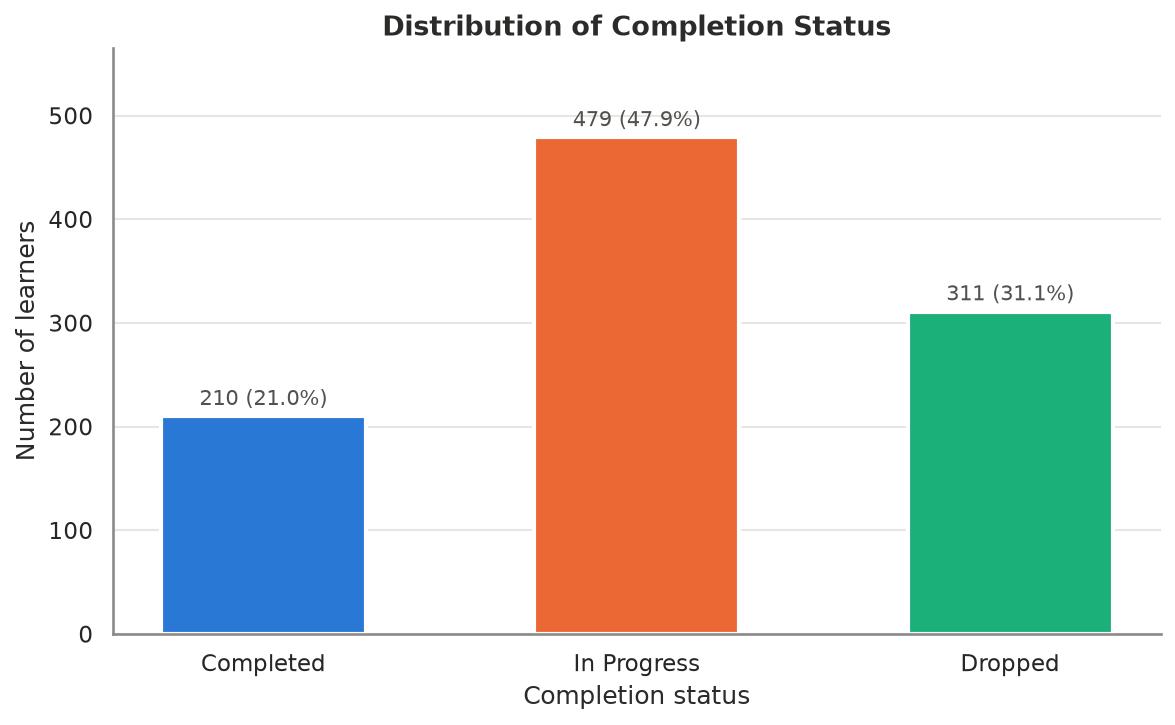

In [12]:
display(results["status"])
display(Image(filename=str(viz.plot_completion_distribution(results["status"]))))

### 5.3 Module-wise Performance

,learners,completion_rate_pct,avg_quiz_score,avg_hours,avg_lesson_progress_pct,avg_activity,avg_engagement_score,dropout_rate_pct
course_module,,,,,,,,
SQL,205,26.8,57.5,14.0,61.9,53.6,42.9,34.6
Data Analytics,210,21.0,53.3,15.7,57.5,52.1,42.4,31.9
Web Development,188,20.2,53.2,21.3,55.9,50.7,45.5,29.8
Python,199,18.6,53.7,17.9,57.3,50.1,43.1,31.7
Java,198,18.2,48.9,17.8,52.7,50.3,41.5,27.3


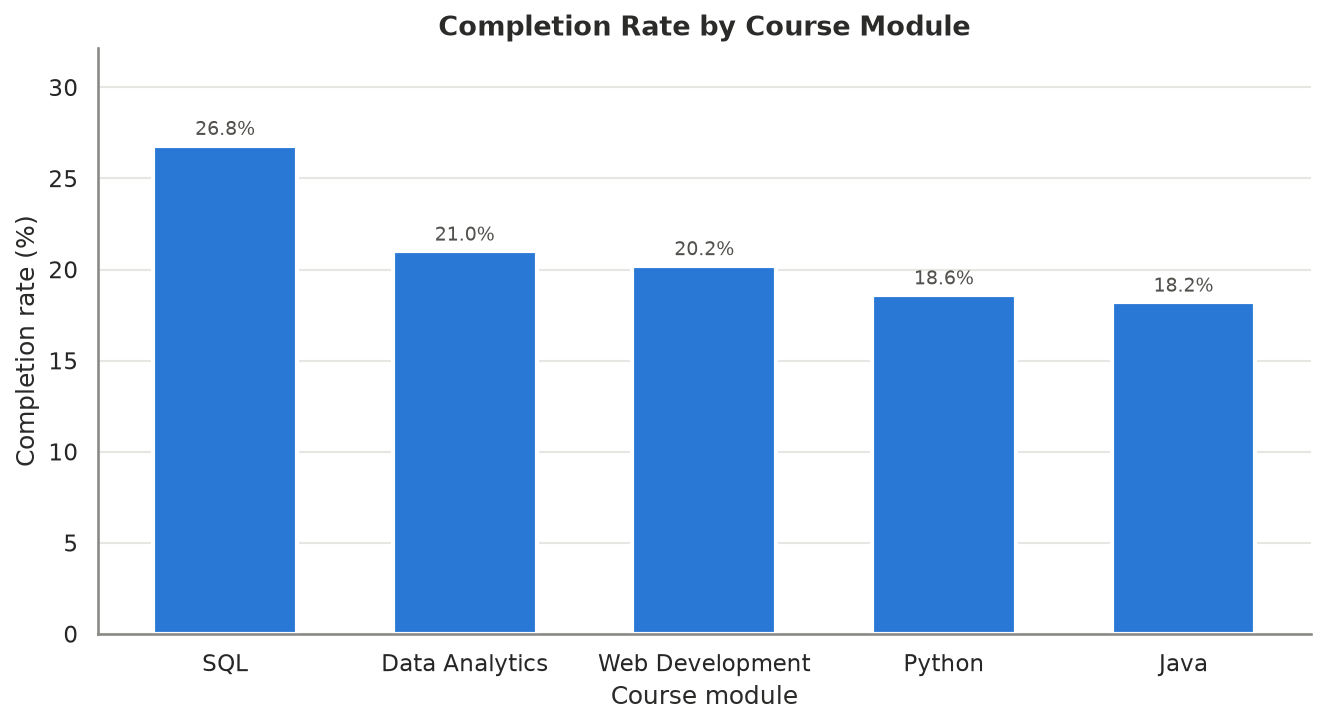

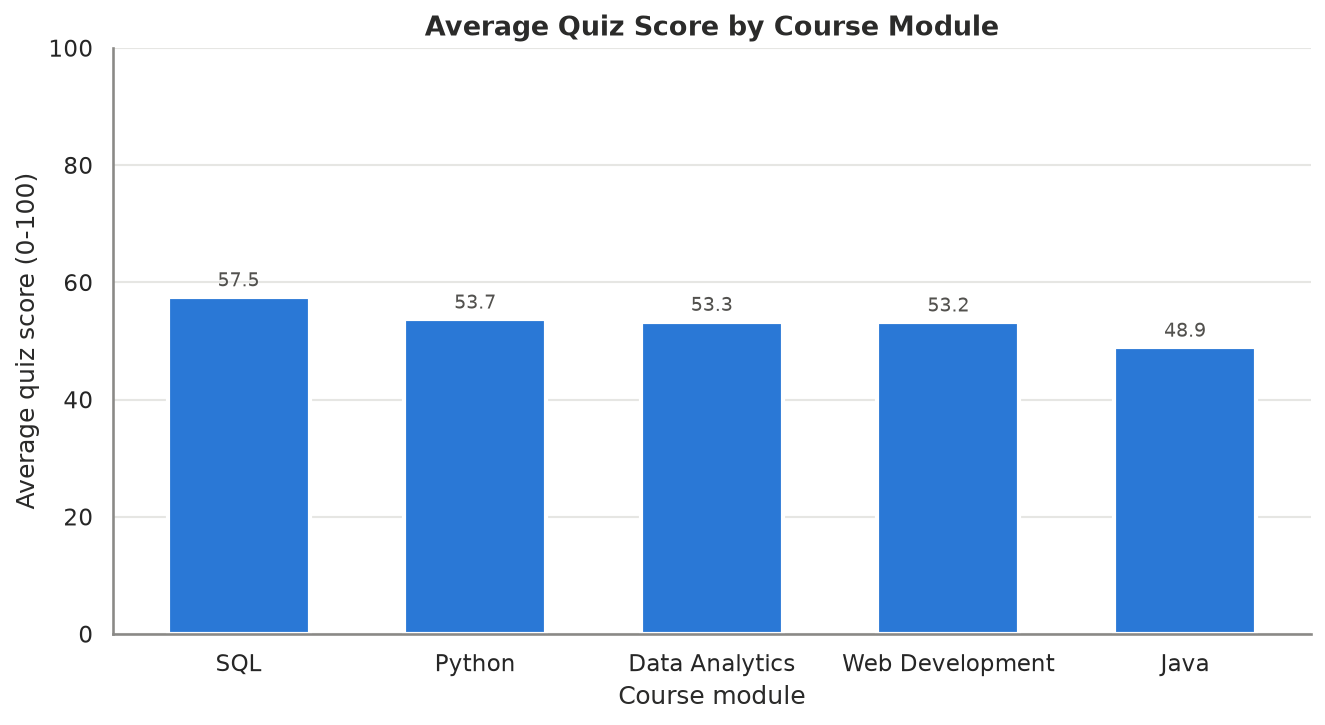

In [13]:
display(results["module"])
display(Image(filename=str(viz.plot_module_completion(results["module"]))))
display(Image(filename=str(viz.plot_module_quiz_score(results["module"]))))

### 5.4 Learning Hours vs Quiz Score

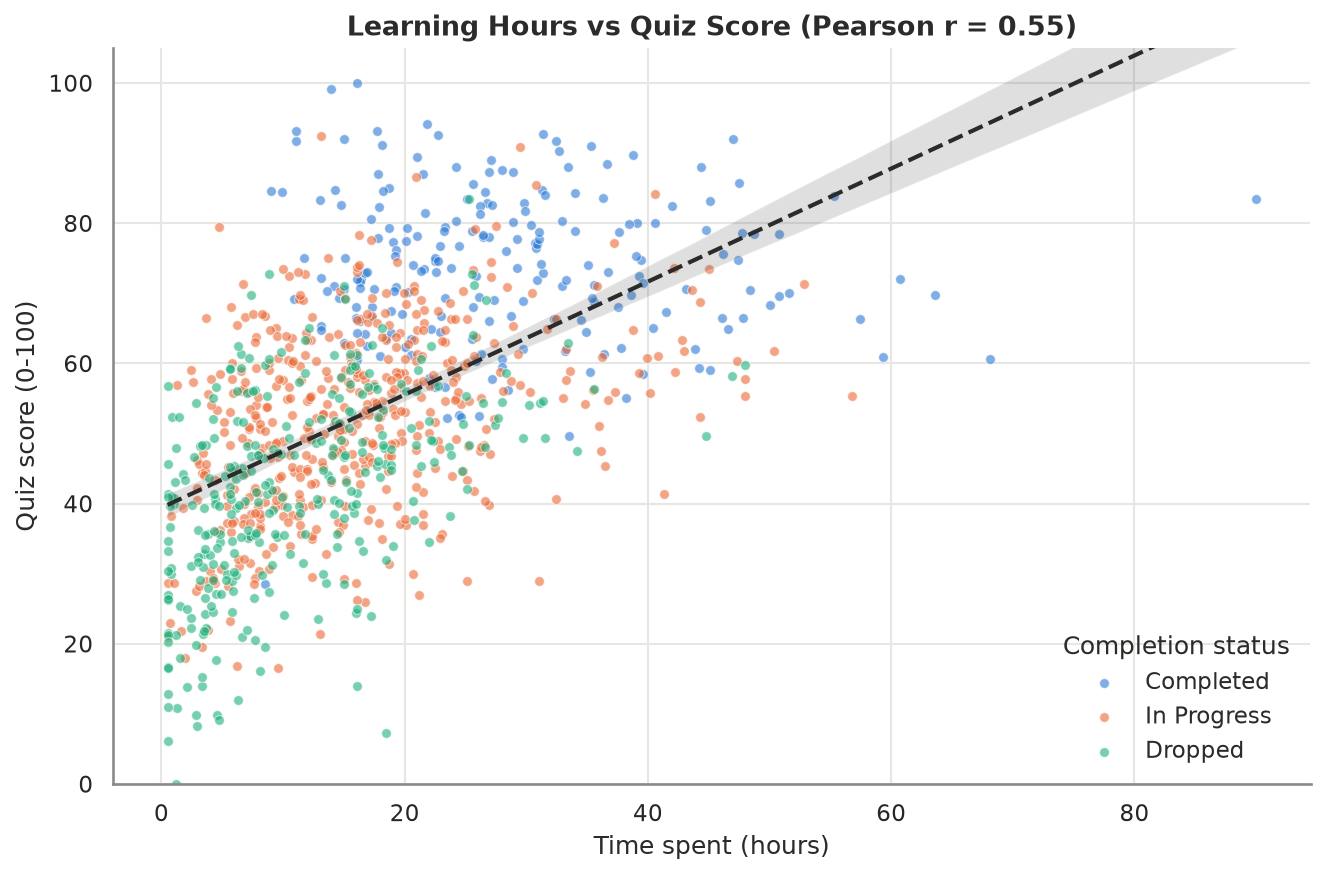

Pearson r (hours vs quiz score): 0.553


In [14]:
display(Image(filename=str(viz.plot_hours_vs_score(data))))
print("Pearson r (hours vs quiz score):", round(data["time_spent_hours"].corr(data["quiz_score"]), 3))

### 5.5 Device Analysis

,learners,completion_rate_pct,avg_quiz_score,avg_hours,avg_lesson_progress_pct,avg_activity,avg_engagement_score,dropout_rate_pct
device_type,,,,,,,,
Desktop,172,24.4,54.3,18.3,60.1,52.8,45.6,23.3
Laptop,422,22.5,53.3,17.4,59.2,52.0,44.2,29.9
Tablet,88,21.6,53.3,17.9,55.0,51.2,42.6,35.2
Mobile,318,17.0,52.8,16.3,53.3,49.9,40.2,35.8


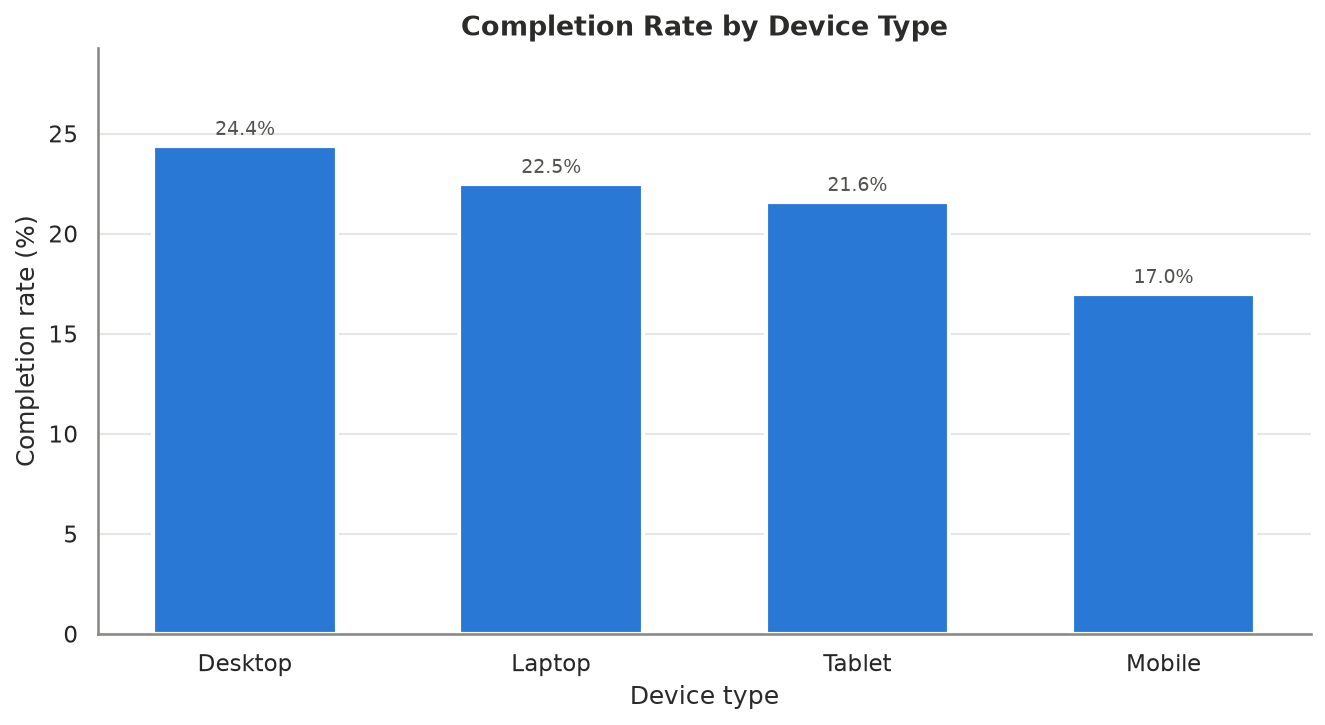

In [15]:
display(results["device"])
display(Image(filename=str(viz.plot_device_completion(results["device"]))))

### 5.6 Age-group Analysis

,learners,completion_rate_pct,avg_quiz_score,avg_hours,avg_lesson_progress_pct,avg_activity,avg_engagement_score,dropout_rate_pct
age_group,,,,,,,,
18-24,385,20.5,53.9,17.8,57.4,51.5,43.7,31.9
25-34,311,24.4,53.8,17.7,58.7,52.3,44.2,30.5
35-44,186,18.3,50.8,15.8,53.4,49.1,39.9,33.3
45+,118,17.8,54.0,16.8,57.6,52.2,42.6,26.3


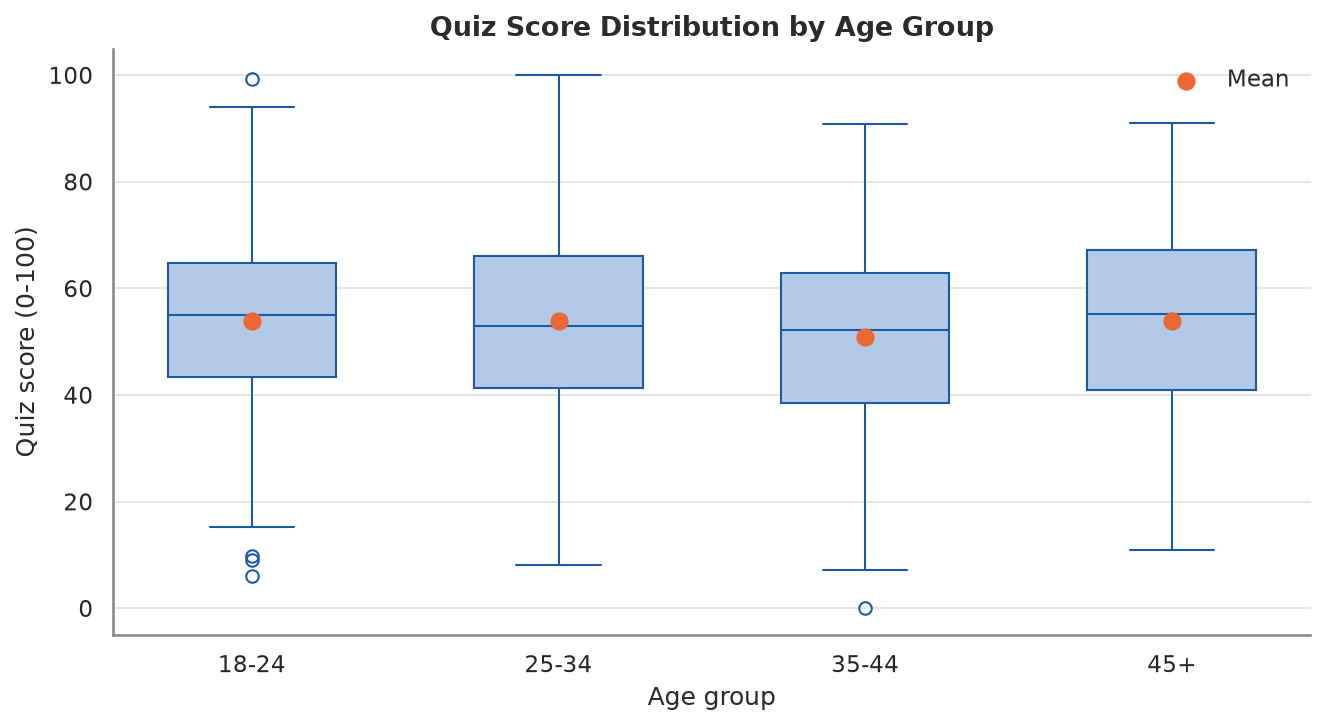

In [16]:
display(results["age"])
display(Image(filename=str(viz.plot_age_quiz_score(data))))

### 5.7 Engagement Analysis
How do completion and quiz scores change across engagement categories?

,learners,avg_engagement_score,completion_rate_pct,avg_quiz_score,avg_hours,inactive_pct
engagement_category,,,,,,
Low,488,19.5,0.2,41.5,9.1,48.6
Medium,308,53.7,12.3,59.1,20.0,24.4
High,204,83.3,83.8,73.0,32.5,30.9


engagement_category,Low,Medium,High
course_module,,,
Data Analytics,50.5,30.5,19.0
Java,50.5,30.3,19.2
Python,47.2,33.7,19.1
SQL,48.8,31.2,20.0
Web Development,46.8,28.2,25.0


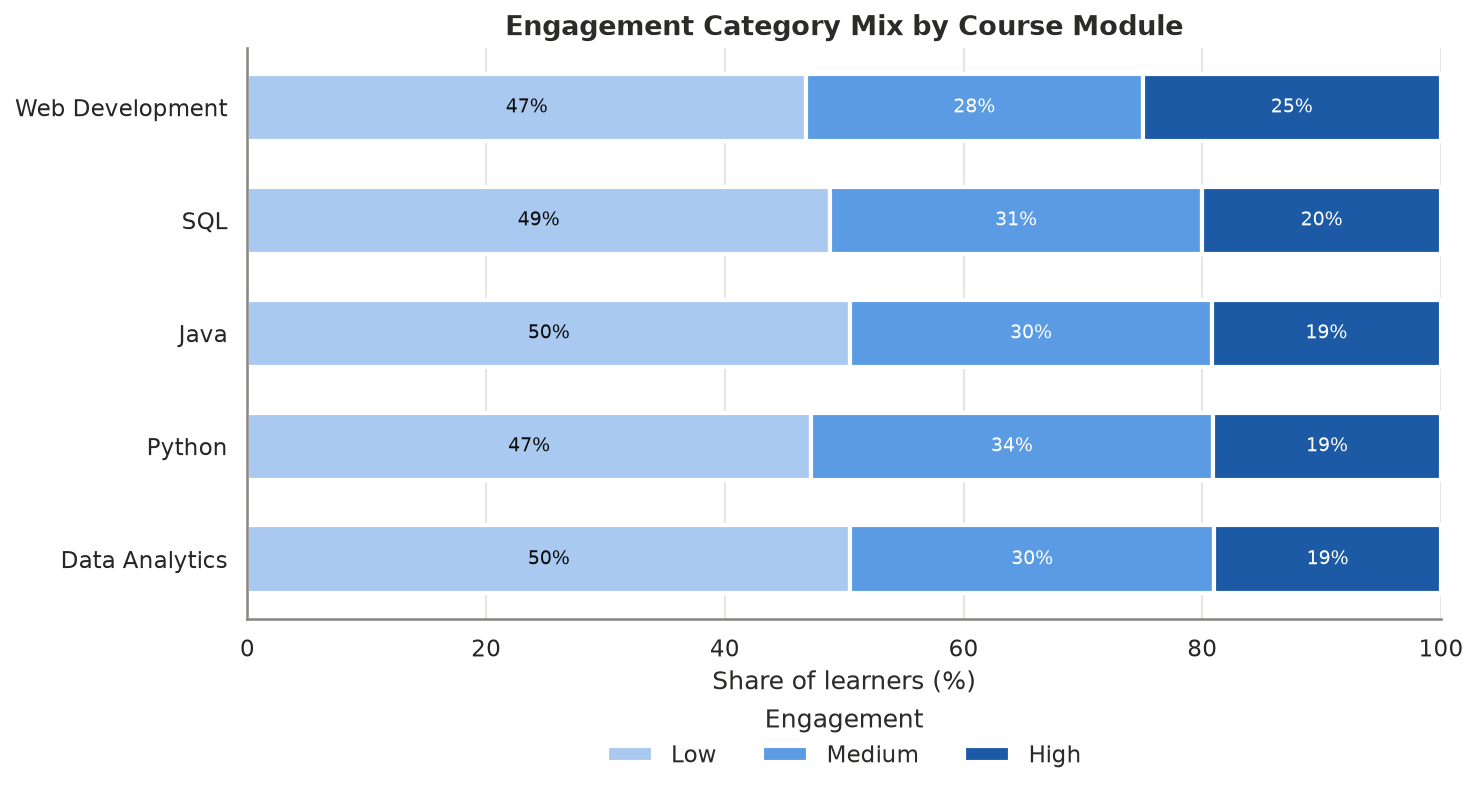

In [17]:
display(results["engagement_outcomes"])
display(results["engagement_module"])
display(Image(filename=str(viz.plot_engagement_by_module(results["engagement_module"]))))

### 5.8 Correlation Analysis

,time_spent_hours,activity_count,lesson_progress_pct,video_completion_pct,quiz_score,last_active_days,engagement_score,is_completed
time_spent_hours,1.00,0.64,0.69,0.65,0.55,-0.24,0.84,0.49
activity_count,0.64,1.00,0.89,0.85,0.81,-0.32,0.92,0.71
lesson_progress_pct,0.69,0.89,1.00,0.94,0.84,-0.34,0.95,0.74
video_completion_pct,0.65,0.85,0.94,1.00,0.81,-0.35,0.90,0.64
quiz_score,0.55,0.81,0.84,0.81,1.00,-0.31,0.81,0.61
last_active_days,-0.24,-0.32,-0.34,-0.35,-0.31,1.00,-0.33,-0.12
engagement_score,0.84,0.92,0.95,0.90,0.81,-0.33,1.00,0.71
is_completed,0.49,0.71,0.74,0.64,0.61,-0.12,0.71,1.00


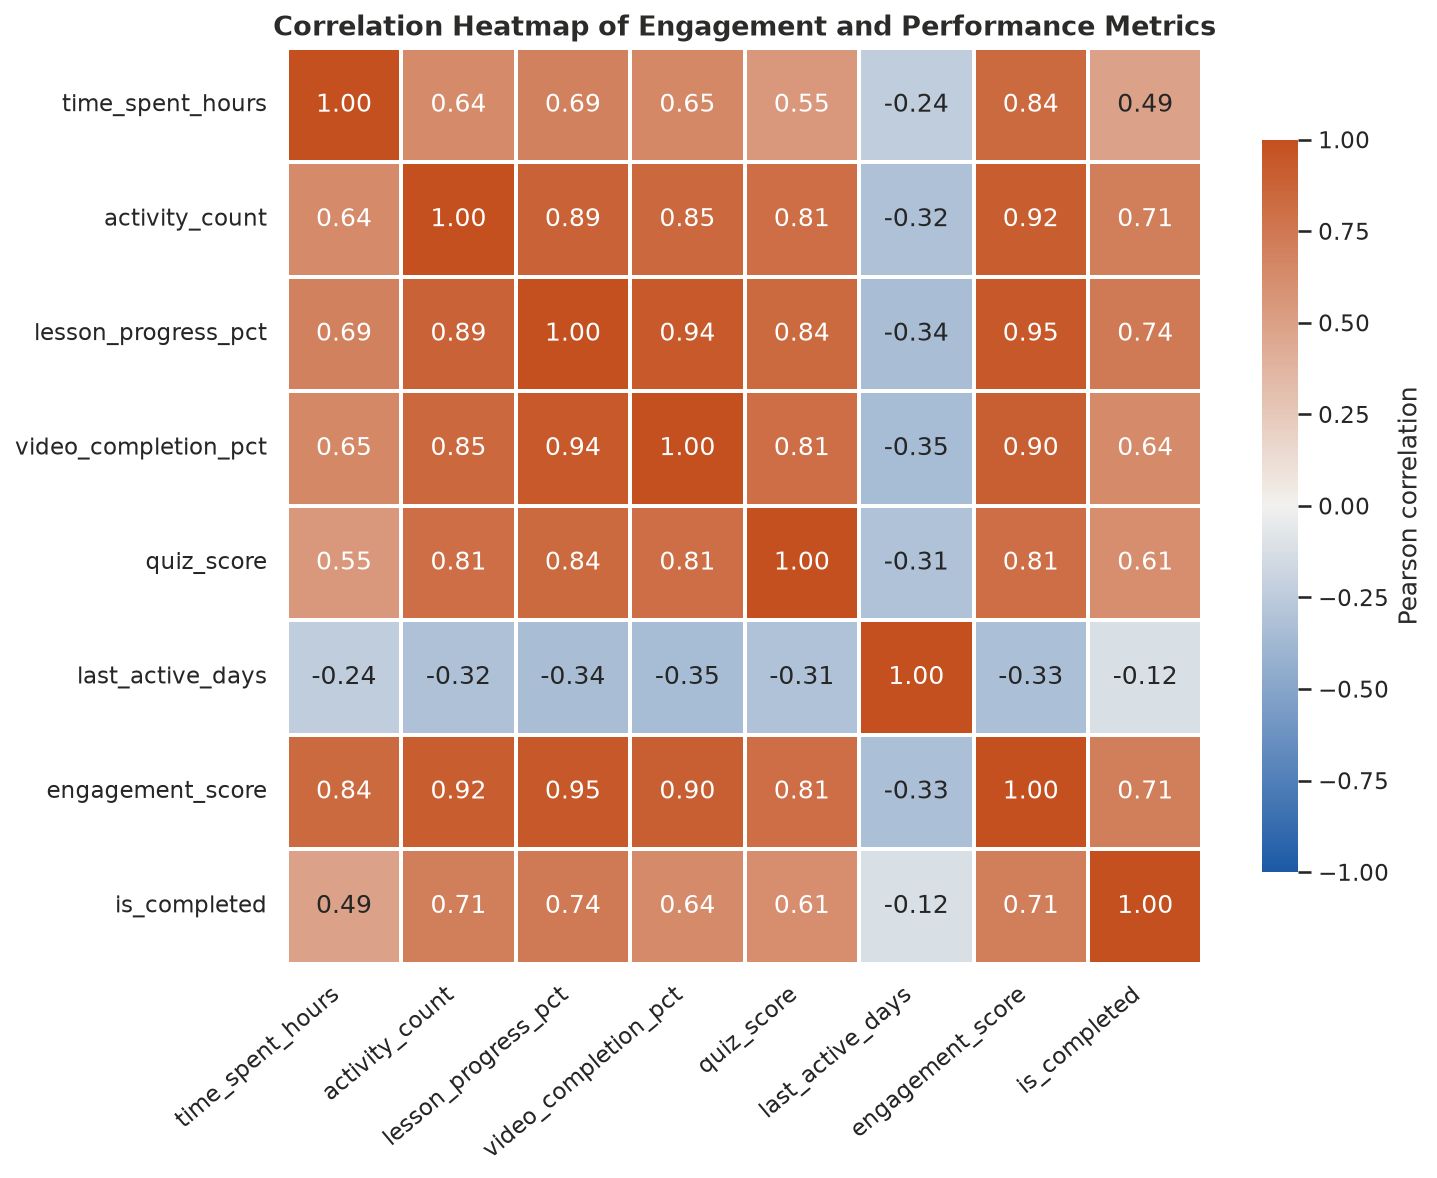

In [18]:
display(results["correlation"])
display(Image(filename=str(viz.plot_correlation_heatmap(results["correlation"]))))

## 6. Insights and Recommendations
All statements below are generated from the calculated values above.

In [19]:
insight_dict = generate_insights(data, results)
save_insights(insight_dict)
display(Markdown("### Key Insights\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(insight_dict["insights"], 1))))
display(Markdown("### Recommendations\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(insight_dict["recommendations"], 1))))

[insights] Saved reports/insights.md


### Key Insights
1. **Overall performance:** 1000 learners were analysed. The overall completion rate is 21.0%, 47.9% are still in progress and 31.1% have dropped out. The average quiz score is 53.3 and learners spent 17.3 hours on average (17,255.6 hours in total).
2. **Module gap:** SQL has the highest completion rate (26.8%) and Java the lowest (18.2%), a gap of 8.6 percentage points. Average quiz scores range from 48.9 (Java) to 57.5 (SQL).
3. **Learning time and scores:** time spent shows a moderate positive correlation with quiz score (r = 0.55); lesson progress vs quiz score has r = 0.84. More study time is associated with better results, but it does not explain all of the variation.
4. **Activity and completion:** activity count correlates with completion at r = 0.71. High-engagement learners complete at 83.8% versus 0.2% for low-engagement learners, and score 73.0 vs 41.5 on quizzes.
5. **Device effect:** Desktop users have the highest completion rate (24.4%), while Mobile users have the lowest (17.0%) and a dropout rate of 35.8%.
6. **Age groups:** the 45+ group has the highest average quiz score (54.0) and 35-44 the lowest (50.8). The difference is 3.2 points, so age is a minor factor compared with engagement.
7. **Inactivity risk:** 375 learners (37.5%) have not been active for more than 30 days; 304 of them have not completed their course. Days since last activity correlates with completion at r = -0.12.
8. **Engagement distribution:** 48.8% of learners fall in the Low engagement category (average engagement score overall = 43.0).

### Recommendations
1. **Re-engagement campaign:** send automated reminders / mentor check-ins to learners inactive for more than 30 days - this targets 304 learners who have not completed.
2. **Review the Java module:** it has the lowest completion rate (18.2%). Break long lessons into shorter units, add practice exercises and revisit the difficulty curve; use SQL as a design benchmark.
3. **Improve the Mobile experience:** Mobile learners complete less often (17.0% vs 24.4% on Desktop). Optimise video length, offline access and quiz layout for this device.
4. **Early-warning dashboard:** use the engagement score as a weekly risk flag - learners in the Low category (48.8% of the cohort) should be contacted before they drop out.
5. **Targeted quiz support for Java:** it has the lowest average quiz score (48.9); add worked examples, hints and retry-based practice quizzes.
6. **Encourage regular activity:** because activity count and learning time are positively linked to completion and scores, introduce streaks, discussion prompts and weekly goals that reward consistent participation.
7. **Assessment quality check:** 2 learners completed their course with a quiz score below 50 - consider a minimum score requirement or extra revision before completion.

## 7. Conclusion
Engagement behaviours (activity, learning time and lesson progress) are strongly associated with course completion
and quiz performance. Learners with low engagement or long inactivity are the main dropout risk, so early-warning
monitoring and targeted support give the largest expected benefit. Module- and device-level gaps show where course
design should improve.

**Limitations:** the data is synthetic, correlation is not causation, and median imputation slightly reduces variance.

The full academic report is in `reports/analysis_report.md`.